# IC3 · CP2 · Stratul de reprezentare
## S1 · Twin de mentenanță pentru motorul turbofan (NASA C-MAPSS)

**Autor:** Mutu Mihaela

La CP1 am încărcat și verificat datele. La CP2 răspundem la trei întrebări:

1. **Reprezentarea:** în ce formă intră datele în model? Comparăm două variante ale aceleiași ferestre de 30 de cicluri: fereastra brută și statistici calculate pe ea.
2. **Baseline-ul:** ce rezultat obțin metodele simple? Orice model de la CP3 trebuie să le bată.
3. **Protocolul:** cum separăm antrenarea de evaluare, ca rezultatul să fie onest?

Lucrăm pe subsetul **FD001** (un regim de zbor, un mod de defect). Celelalte subseturi vin la CP4, la cazurile nevăzute.


## 1. Configurare

Aceleași reguli ca la CP1: notebook-ul caută singur folderul `CMAPSSData`. Parametrii experimentului sunt toți aici, ca să poată fi schimbați într-un singur loc.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

DATA_DIR = None        # None = caută automat; altfel, de exemplu: Path.home() / "Desktop" / "master" / "IC3" / "CMAPSSData"
SUBSET = "FD001"
W = 30                 # lungimea ferestrei, în cicluri
CAP = 125              # plafonul RUL folosit ca țintă la antrenare
SEEDS = [42, 43, 44, 45, 46]   # 5 împărțiri antrenare / validare, fiecare cu alt seed
VAL_FRAC = 0.2
RF_PARAMS = dict(n_estimators=200, max_features="sqrt", min_samples_leaf=5, n_jobs=-1)

REPORTS = Path("reports"); REPORTS.mkdir(exist_ok=True)

def find_data_dir():
    candidates = [
        Path("CMAPSSData"),
        Path("..") / "CMAPSSData",
        Path.home() / "Desktop" / "master" / "IC3" / "CMAPSSData",
        Path.home() / "Desktop" / "master" / "CMAPSSData",
        Path.home() / "Library" / "Mobile Documents" / "com~apple~CloudDocs" / "Desktop" / "master" / "CMAPSSData",
    ]
    for c in candidates:
        if c.exists():
            hit = next(iter(sorted(c.rglob("train_FD001.txt"))), None)
            if hit is not None:
                return hit.parent
    raise FileNotFoundError("Nu am găsit CMAPSSData. Scrie calea în DATA_DIR.")

DATA_DIR = Path(DATA_DIR).expanduser() if DATA_DIR else find_data_dir()
print("Date:", str(DATA_DIR.resolve()).replace(str(Path.home()), "~"))

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Date: ~/Desktop/master/IC3/CMAPSSData


## 2. Datele FD001 și ținta

Citirea și RUL sunt la fel ca la CP1. Păstrăm cei 14 senzori care variază; ceilalți 7 (s1, s5, s6, s10, s16, s18, s19) au cel mult 2 valori în tot setul de antrenare, deci nu spun nimic despre degradare.

In [2]:
COLS = ["unit", "cycle", "setting_1", "setting_2", "setting_3"] + [f"s{i}" for i in range(1, 22)]

def read(name):
    return pd.read_csv(DATA_DIR / name, sep=r"\s+", header=None, names=COLS)

train = read(f"train_{SUBSET}.txt")
test = read(f"test_{SUBSET}.txt")
rul_test = pd.read_csv(DATA_DIR / f"RUL_{SUBSET}.txt", sep=r"\s+", header=None)[0].to_numpy()
train["rul"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]

SENSORS = [f"s{i}" for i in range(1, 22)]
KEEP = [c for c in SENSORS if train[c].nunique() > 2]
assert len(KEEP) == 14, KEEP
assert test.groupby("unit")["cycle"].max().min() >= W, "un motor de test are mai puțin de W cicluri"
print(f"Antrenare: {train['unit'].nunique()} motoare, {len(train)} rânduri")
print(f"Test: {test['unit'].nunique()} motoare, {len(test)} rânduri")
print("Senzori păstrați:", KEEP)

Antrenare: 100 motoare, 20631 rânduri
Test: 100 motoare, 13096 rânduri
Senzori păstrați: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


### Ținta plafonată la 125 de cicluri

La începutul vieții, motorul e sănătos și senzorii nu arată încă nicio degradare. Un model nu are de unde ști dacă mai are 300 sau 200 de cicluri. De aceea ținta de antrenare este plafonată: RUL = min(RUL real, 125). Valoarea 125 e cea folosită de Zhang et al. 2022 și Robinson 2026; Ellefsen et al. 2019 au ales între 115 și 135. Pe setul de test comparăm cu RUL-ul **real**, neplafonat, pentru că asta contează pentru client.

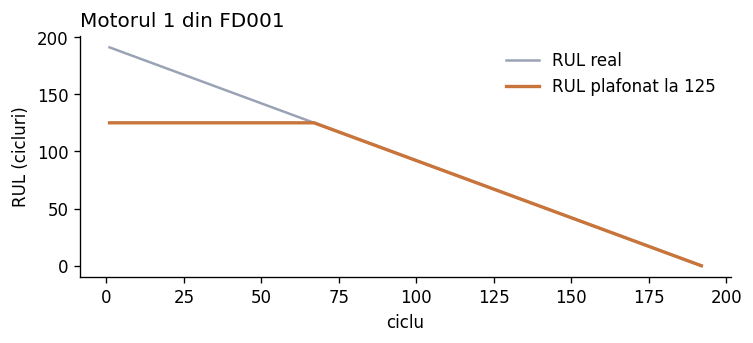

In [3]:
g = train[train["unit"] == 1]
fig, ax = plt.subplots(figsize=(7, 2.6), dpi=120)
ax.plot(g["cycle"], g["rul"], label="RUL real", color="#9AA3B5")
ax.plot(g["cycle"], np.minimum(g["rul"], CAP), label=f"RUL plafonat la {CAP}", color="#C8743A", lw=2)
ax.set_xlabel("ciclu"); ax.set_ylabel("RUL (cicluri)"); ax.set_title("Motorul 1 din FD001", loc="left")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 3. Cele două reprezentări

Pentru fiecare moment *t* al unui motor luăm ultimele **W = 30 de cicluri** din cei 14 senzori. Senzorii sunt standardizați (medie 0, abatere 1) cu media și abaterea calculate **doar pe motoarele de antrenare** ale fiecărei împărțiri.

| | Reprezentare | Ce intră în model | Dimensiune |
|---|---|---|---|
| **B (aleasă)** | statistici pe fereastră | pentru fiecare senzor: ultima valoare, media, abaterea și panta pe cele 30 de cicluri | 14 × 4 = 56 de valori |
| **A (alternativa)** | fereastra brută | toate cele 30 × 14 valori, una după alta | 420 de valori |

Fereastra brută este intrarea obișnuită pentru rețelele secvențiale (LSTM, CNN) din literatură. Statisticile sunt mai compacte și fiecare valoare are un sens fizic („cât de repede crește T50”), util la explicații (CP5). Alegerea se face pe rezultatele de mai jos.

In [4]:
def make_windows(df, last_only=False):
    # Întoarce ferestrele (n, W, 14), ținta, ciclul curent și motorul pentru fiecare fereastră.
    X, y, t, u = [], [], [], []
    for unit, g in df.groupby("unit"):
        a = g[KEEP].to_numpy()
        c = g["cycle"].to_numpy()
        r = g["rul"].to_numpy() if "rul" in g else np.full(len(g), np.nan)
        ends = [len(g)] if last_only else range(W, len(g) + 1)
        for e in ends:
            X.append(a[e - W:e]); y.append(r[e - 1]); t.append(c[e - 1]); u.append(unit)
    return np.stack(X), np.array(y), np.array(t), np.array(u)

def rep_window(Z):            # A: fereastra brută, aplatizată
    return Z.reshape(len(Z), -1)

def rep_stats(Z):             # B: ultima valoare, medie, abatere, pantă
    tt = np.arange(W) - (W - 1) / 2
    slope = (Z * tt[None, :, None]).sum(axis=1) / (tt ** 2).sum()
    return np.concatenate([Z[:, -1, :], Z.mean(axis=1), Z.std(axis=1), slope], axis=1)

X_all, y_all, t_all, u_all = make_windows(train)
X_test, _, t_test, u_test = make_windows(test, last_only=True)
print("Ferestre de antrenare:", X_all.shape, " Ferestre de test (ultimul ciclu):", X_test.shape)
print("A, fereastra brută:", rep_window(X_all[:2]).shape[1], "valori;  B, statistici:", rep_stats(X_all[:2]).shape[1], "valori")

Ferestre de antrenare: (17731, 30, 14)  Ferestre de test (ultimul ciclu): (100, 30, 14)
A, fereastra brută: 420 valori;  B, statistici: 56 valori


## 4. Protocolul experimental

- **Împărțirea:** pe motoare întregi. 80% din motoarele de antrenare antrenează modelul, 20% îl validează. Un motor nu apare niciodată în ambele părți: ciclurile vecine ale aceluiași motor sunt aproape identice, iar o împărțire pe rânduri ar umfla rezultatele.
- **De ce nu temporal sau LOYO:** nu există timp calendaristic sau ani. Fiecare motor are propria axă de timp, de la 1 la defectare. Întrebarea twin-ului este „cât trăiește un motor **nou**”, deci echivalentul LOYO este **motorul nevăzut**: antrenăm pe unele motoare și testăm pe altele.
- **Repetări:** 5 împărțiri, cu seed-urile 42–46. Raportăm media ± abaterea, ca să vedem cât depinde rezultatul de motoarele alese.
- **Testul final:** setul de test NASA (100 de motoare), evaluat doar la ultimul ciclu observat, comparat cu RUL-ul real. Nu se folosește la nicio alegere.
- **Metrici:** RMSE în cicluri (cât greșim în medie) și scorul NASA, care penalizează mai tare estimările întârziate (constante 13 și 10, Saxena et al. 2008). La amândouă, mai mic înseamnă mai bine.

**Baseline-urile**, de la cel mai simplu la cel mai puternic:

| Baseline | Ce prezice | Echivalentul din planul cursului |
|---|---|---|
| RUL mediu constant | media RUL-ului (plafonat) din antrenare, pentru orice motor | cea mai naivă predicție |
| Climatologie (vârstă) | durata medie de viață a flotei minus ciclurile deja zburate | climatologia; este și logica mentenanței la intervale fixe |
| Regresie liniară (B) | Ridge pe statisticile ferestrei | model liniar |
| Random Forest (A) | RF pe fereastra brută | RF, „clasicul puternic” |
| Random Forest (B) | RF pe statisticile ferestrei | RF, „clasicul puternic” |

**Persistența** („mâine = azi”) nu se aplică: RUL nu se măsoară în timpul funcționării, deci nu există o valoare de ieri pe care să o repetăm. Climatologia ține locul ei ca baseline naiv.

In [5]:
def rmse(pred, true):
    return float(np.sqrt(np.mean((pred - true) ** 2)))

def nasa_score(pred, true):
    d = pred - true                     # d > 0: estimare întârziată, penalizată mai tare
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def split_engines(units, seed):
    units = np.sort(np.asarray(units))
    rng = np.random.default_rng(seed)
    val = np.sort(rng.choice(units, size=int(round(len(units) * VAL_FRAC)), replace=False))
    return np.setdiff1d(units, val), val

## 5. Rularea baseline-urilor

Pentru fiecare seed: împărțim motoarele, standardizăm pe partea de antrenare, antrenăm fiecare baseline, apoi îl evaluăm pe motoarele de validare (toate ferestrele) și pe testul NASA (ultimul ciclu).

In [6]:
rows, preds_test = [], {}
y_cap = np.minimum(y_all, CAP)
t0 = time.time()
for seed in SEEDS:
    tr_units, va_units = split_engines(train["unit"].unique(), seed)
    assert not set(tr_units) & set(va_units)
    m_tr, m_va = np.isin(u_all, tr_units), np.isin(u_all, va_units)

    flat = X_all[m_tr].reshape(-1, len(KEEP))
    mu, sd = flat.mean(axis=0), flat.std(axis=0)          # doar din motoarele de antrenare
    Z_all, Z_test = (X_all - mu) / sd, (X_test - mu) / sd

    mean_rul = y_cap[m_tr].mean()
    mean_life = train[train["unit"].isin(tr_units)].groupby("unit")["cycle"].max().mean()
    climat = lambda t: np.clip(mean_life - t, 0, CAP)

    out = {
        "RUL mediu constant": (np.full(m_va.sum(), mean_rul), np.full(len(X_test), mean_rul)),
        "Climatologie (vârstă)": (climat(t_all[m_va]), climat(t_test)),
    }
    models = {
        "Regresie liniară (B)": (Ridge(alpha=1.0), rep_stats),
        "Random Forest (A)": (RandomForestRegressor(random_state=seed, **RF_PARAMS), rep_window),
        "Random Forest (B)": (RandomForestRegressor(random_state=seed, **RF_PARAMS), rep_stats),
    }
    for name, (model, rep) in models.items():
        model.fit(rep(Z_all[m_tr]), y_cap[m_tr])
        out[name] = (np.clip(model.predict(rep(Z_all[m_va])), 0, None), np.clip(model.predict(rep(Z_test)), 0, None))

    for name, (p_va, p_te) in out.items():
        rows.append({"seed": seed, "metodă": name,
                     "RMSE validare": rmse(p_va, y_cap[m_va]),
                     "RMSE test": rmse(p_te, rul_test),
                     "scor NASA test": nasa_score(p_te, rul_test)})
        preds_test.setdefault(name, []).append(p_te)
    print(f"seed {seed} gata ({time.time() - t0:.0f} s)")

runs = pd.DataFrame(rows)
runs.to_csv(REPORTS / "cp2_runs.csv", index=False)

seed 42 gata (8 s)
seed 43 gata (15 s)
seed 44 gata (21 s)
seed 45 gata (27 s)
seed 46 gata (33 s)


## 6. Rezultate

Media ± abaterea pe cele 5 împărțiri. RMSE de validare: pe toate ferestrele motoarelor de validare, față de ținta plafonată. RMSE și scorul de test: pe ultimul ciclu al celor 100 de motoare de test NASA, față de RUL-ul real.

In [7]:
ORDER = ["RUL mediu constant", "Climatologie (vârstă)", "Regresie liniară (B)", "Random Forest (A)", "Random Forest (B)"]
agg = runs.groupby("metodă")[["RMSE validare", "RMSE test", "scor NASA test"]].agg(["mean", "std"]).loc[ORDER]
table = pd.DataFrame({
    "RMSE validare (cicluri)": [f"{m:.2f} ± {s:.2f}" for m, s in agg["RMSE validare"].to_numpy()],
    "RMSE test (cicluri)": [f"{m:.2f} ± {s:.2f}" for m, s in agg["RMSE test"].to_numpy()],
    "scor NASA test": [f"{m:,.0f} ± {s:,.0f}" for m, s in agg["scor NASA test"].to_numpy()],
}, index=ORDER)
table.to_csv(REPORTS / "cp2_results.csv")
summary = {k: {c: {"mean": float(agg.loc[k, (c, "mean")]), "std": float(agg.loc[k, (c, "std")])}
               for c in ["RMSE validare", "RMSE test", "scor NASA test"]} for k in ORDER}
(REPORTS / "cp2_results.json").write_text(json.dumps(
    {"subset": SUBSET, "window": W, "cap": CAP, "seeds": SEEDS, "val_frac": VAL_FRAC,
     "sensors": KEEP, "rf_params": RF_PARAMS, "results": summary}, indent=1, ensure_ascii=False))
table

,RMSE validare (cicluri),RMSE test (cicluri),scor NASA test
RUL mediu constant,41.80 ± 0.08,41.87 ± 0.04,"18,803 ± 495"
Climatologie (vârstă),32.77 ± 3.37,36.81 ± 0.09,"23,207 ± 184"
Regresie liniară (B),16.78 ± 1.10,16.31 ± 0.12,441 ± 17
Random Forest (A),17.56 ± 2.17,18.08 ± 0.15,760 ± 44
Random Forest (B),13.13 ± 1.15,13.30 ± 0.14,246 ± 6


### Figura pentru slide-ul 2

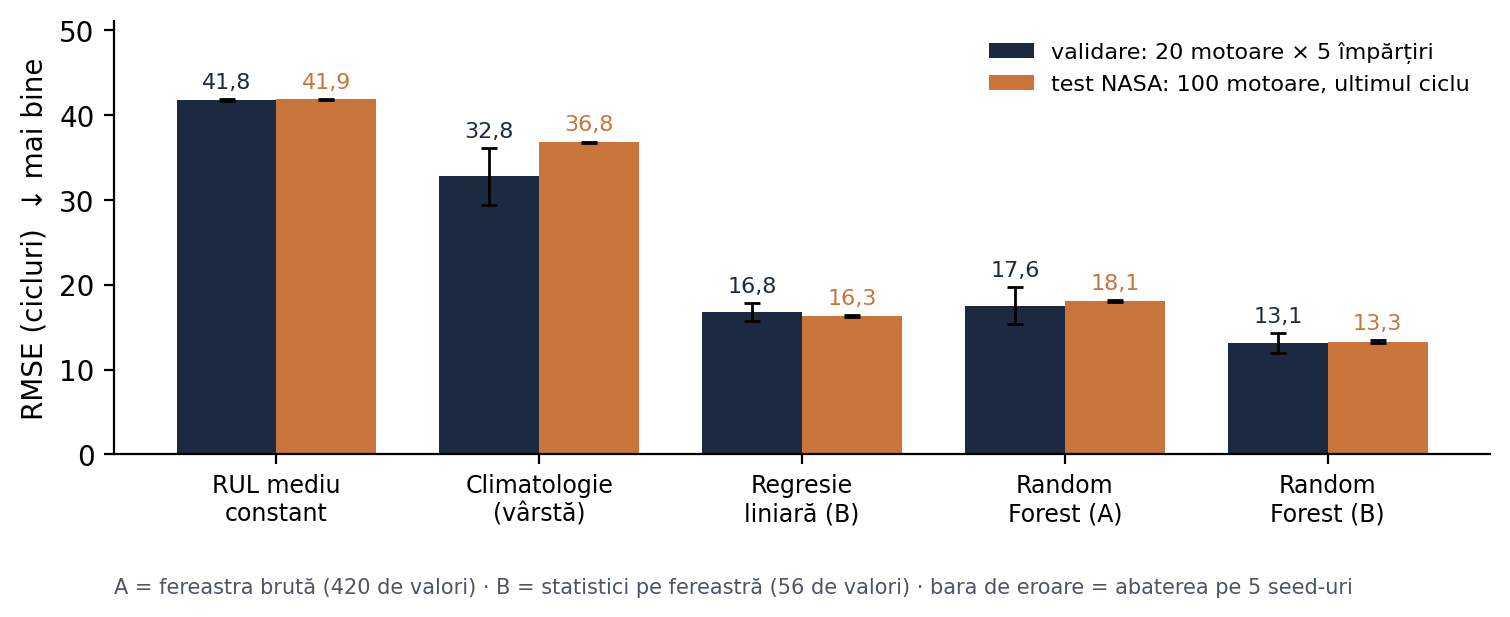

In [8]:
NAVY, ORANGE = "#1B2A41", "#C8743A"
labels = ["RUL mediu\nconstant", "Climatologie\n(vârstă)", "Regresie\nliniară (B)", "Random\nForest (A)", "Random\nForest (B)"]
x = np.arange(len(ORDER)); w = 0.38
fig, ax = plt.subplots(figsize=(7.8, 3.3), dpi=200)
for off, col, color, lab in [(-w / 2, "RMSE validare", NAVY, "validare: 20 motoare × 5 împărțiri"),
                             (w / 2, "RMSE test", ORANGE, "test NASA: 100 motoare, ultimul ciclu")]:
    m, s = agg[col]["mean"].to_numpy(), agg[col]["std"].to_numpy()
    bars = ax.bar(x + off, m, w, yerr=s, capsize=3, color=color, label=lab, error_kw={"elinewidth": 1})
    for b, v, e in zip(bars, m, s):
        ax.text(b.get_x() + b.get_width() / 2, v + e + 0.8, f"{v:.1f}".replace(".", ","),
                ha="center", va="bottom", fontsize=8, color=color)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylabel("RMSE (cicluri)  ↓ mai bine")
ax.set_ylim(0, agg["RMSE test"]["mean"].max() * 1.22)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
ax.text(0.0, -0.32, "A = fereastra brută (420 de valori) · B = statistici pe fereastră (56 de valori) · bara de eroare = abaterea pe 5 seed-uri",
        transform=ax.transAxes, fontsize=7.5, color="#4A5568")
fig.tight_layout()
fig.savefig(REPORTS / "fig_cp2_baselines.png", bbox_inches="tight", facecolor="white")
plt.show()

## 7. Ce reiese

Celula de mai jos scrie concluziile direct din cifre, ca textul să nu rămână în urma rezultatelor dacă rulezi din nou.

In [9]:
def ms(k, c):
    return summary[k][c]["mean"], summary[k][c]["std"]

best = min(ORDER, key=lambda k: summary[k]["RMSE validare"]["mean"])
a_va, b_va = ms("Random Forest (A)", "RMSE validare")[0], ms("Random Forest (B)", "RMSE validare")[0]
chosen = "B (statistici pe fereastră)" if b_va < a_va else "A (fereastra brută)"
print(f"Cel mai bun baseline pe validare: {best}")
print(f"Reprezentarea aleasă: {chosen}. RF pe B are RMSE de validare {b_va:.2f}, RF pe A are {a_va:.2f}.")
for k in ORDER:
    v, vs = ms(k, "RMSE validare"); t, ts = ms(k, "RMSE test"); sc, scs = ms(k, "scor NASA test")
    print(f"  {k:24s} validare {v:6.2f} ± {vs:4.2f} | test {t:6.2f} ± {ts:4.2f} | scor {sc:9.0f} ± {scs:6.0f}")
print(f"Pragul pentru CP3: modelul de inteligență computațională trebuie să bată {best}: "
      f"RMSE de validare sub {ms(best, 'RMSE validare')[0]:.2f} și RMSE de test sub {ms(best, 'RMSE test')[0]:.2f} cicluri.")
print(f"Motoare de test cu RUL real peste {CAP}: {(rul_test > CAP).sum()} din {len(rul_test)} (aici plafonul aduce eroare sigură).")

Cel mai bun baseline pe validare: Random Forest (B)
Reprezentarea aleasă: B (statistici pe fereastră). RF pe B are RMSE de validare 13.13, RF pe A are 17.56.
  RUL mediu constant       validare  41.80 ± 0.08 | test  41.87 ± 0.04 | scor     18803 ±    495
  Climatologie (vârstă)    validare  32.77 ± 3.37 | test  36.81 ± 0.09 | scor     23207 ±    184
  Regresie liniară (B)     validare  16.78 ± 1.10 | test  16.31 ± 0.12 | scor       441 ±     17
  Random Forest (A)        validare  17.56 ± 2.17 | test  18.08 ± 0.15 | scor       760 ±     44
  Random Forest (B)        validare  13.13 ± 1.15 | test  13.30 ± 0.14 | scor       246 ±      6
Pragul pentru CP3: modelul de inteligență computațională trebuie să bată Random Forest (B): RMSE de validare sub 13.13 și RMSE de test sub 13.30 cicluri.
Motoare de test cu RUL real peste 125: 11 din 100 (aici plafonul aduce eroare sigură).
